In [39]:
import matplotlib.pyplot as plt
from algorithms.tss_file import TSSFile
import os

In [40]:
def find_file(filename, search_dir):
    for root, dirs, files in os.walk(search_dir):
        if filename in files:
            return root
    return None

In [41]:
folder = r'\\10.44.21.20\CGDSharedDrive\!USERS\KLS\TV2.3-multipulse\20260804'
tss_file = 'CG2I0003_400V_23uH_2us5us_15Vg_0R0Rg_6p_RT.tss'
path = find_file(tss_file, folder)
tss = TSSFile(path, tss_file, source='Local')
channel_labels = tss.channel_labels
num = 4
print(channel_labels)

{'ch1': 'Vg', 'ch2': 'Vgi', 'ch3': 'Vd', 'ch4': 'IL', 'ch5': 'Ig', 'ch6': 'Is'}


In [42]:
pulse_to_plot = [0, 2, 5]
pulse_width = 5*1e3
time_start = -0.6 *1e3
window_size = 1*1e3

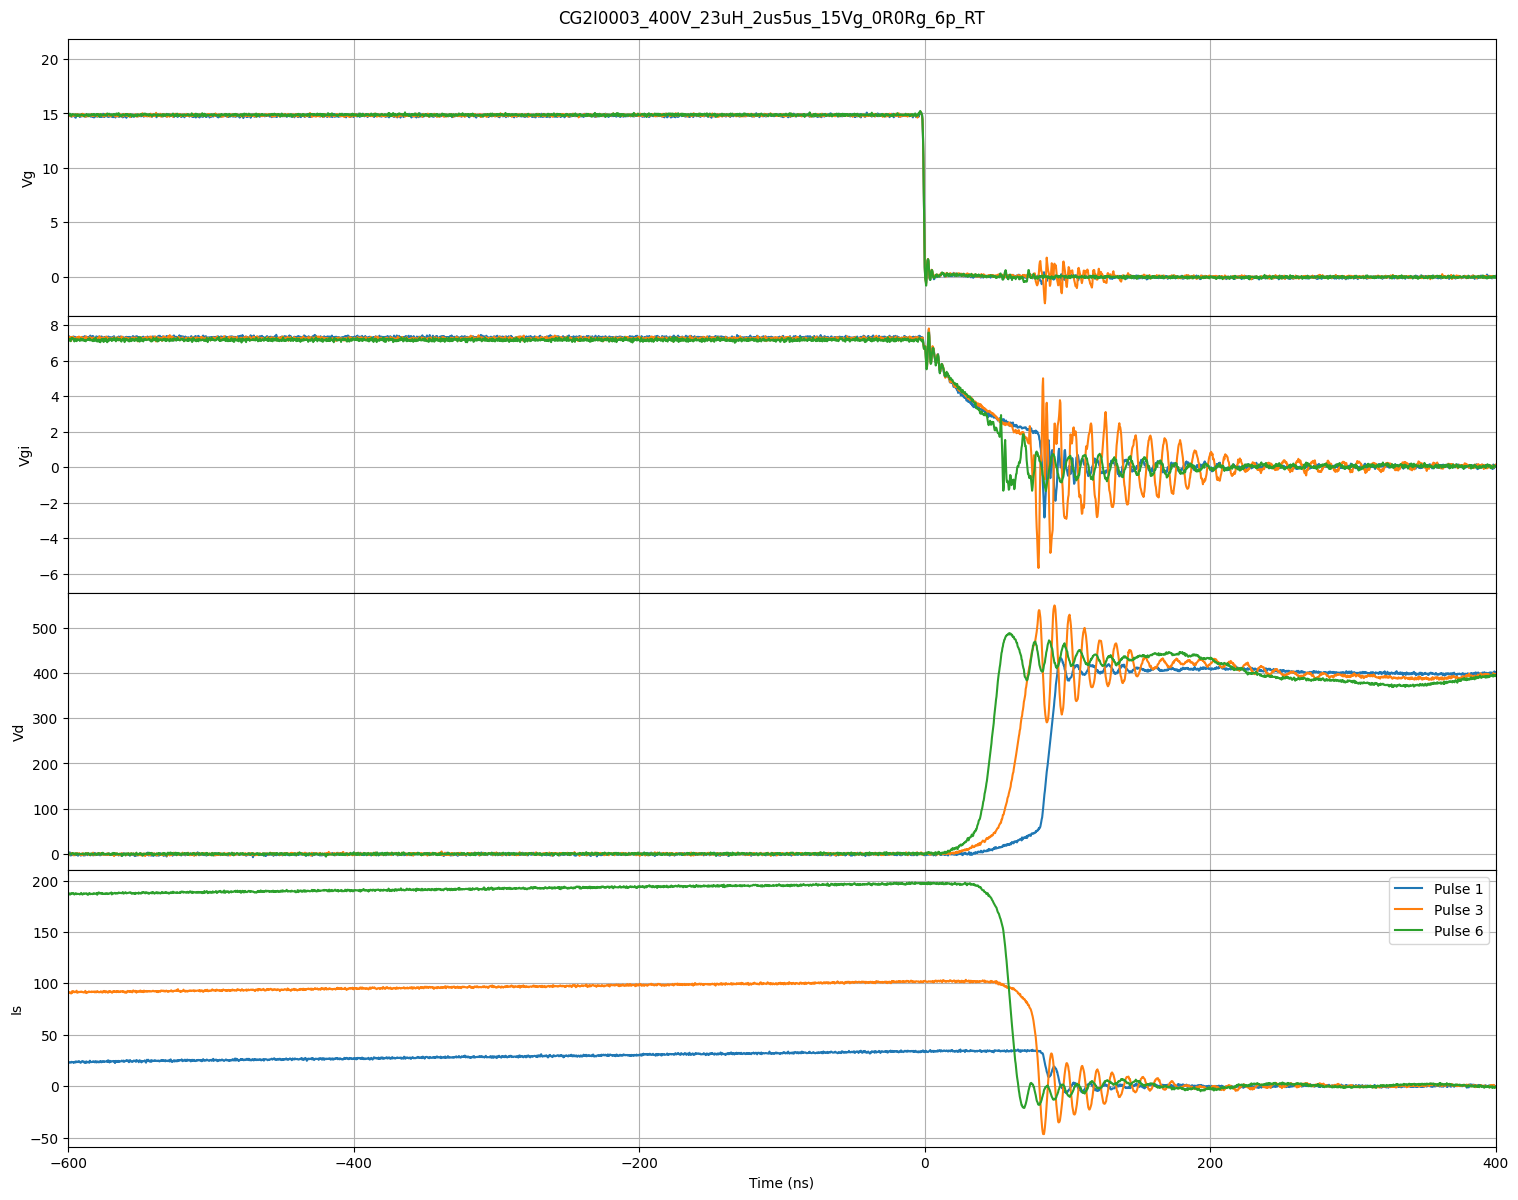

In [43]:
fig, axs = plt.subplots(num, 1, sharex=True, figsize=(15, num*3))
fig.suptitle(tss_file[:-4])
fig.tight_layout()
fig.subplots_adjust(hspace=0)
time = tss.waveforms[list(channel_labels.keys())[0]].time_for_frame()*1e9

for pulse in pulse_to_plot:
    index = 0
    for channel in ['ch1', 'ch2', 'ch3', 'ch6']:
        values = tss.waveforms[channel].values_for_frame(0)
        axs[index].plot(time - pulse_width * pulse, values, label=f'Pulse {pulse + 1}')
        axs[index].set_ylabel(channel_labels[channel])
        axs[index].grid(True)
        index += 1

plt.legend()
plt.xlabel('Time (ns)')
plt.xlim([time_start, window_size + time_start])
#plt.xlim([-1000, 1000])
plt.legend(loc='best')
plt.show()